# Energy Calculation

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
from qss import energy
from qss.distributions import prepare_2D_lattice_data, DistType
import tools.scientific_plot as sp

## 2D Lattice

In [3]:
N = 100
t = -1
t_prim = 0.25
# t_prim = 0

kx = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi
ky = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi

e_k, _, _ = prepare_2D_lattice_data(kx, ky, t, t_prim)

## Energy

In [4]:
mu = Path("chemical_potential_results.csv")
if  mu.exists():
    mu_df = pd.read_csv(mu)
    n = np.unique(mu_df["n"])
    distro = np.unique(mu_df["distro"])
    k_BT = np.unique(mu_df["k_BT"])
    beta = 1/k_BT
    H_a = np.unique(mu_df["H_a"])

    if not "entropy"  in mu_df.columns:
        raise("Lack of the calculated chemical potential! Please run notebook number 2")
    
    if "energy" in mu_df.columns:
        energy_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])
    else:
        mu_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])
        energy_df = energy(mu_df, e_k)
        energy_df.to_csv("chemical_potential_results.csv")

else:
    raise("Lack of the calculated chemical potential! Please run notebook number 2")
energy_df

mu  iterations  converged  \
distro n        k_BT    H_a                                         
FD     0.010000 100.000 0.0    -529.341704          23       True   
       0.035128 100.000 0.0    -402.428638          19       True   
       0.060256 100.000 0.0    -347.180857          22       True   
       0.085385 100.000 0.0    -311.020926          23       True   
       0.110513 100.000 0.0    -283.902851          23       True   
...                                    ...         ...        ...   
SSL    0.889487 0.001   1000.0    2.052969          21       True   
       0.914615 0.001   1000.0    2.246511          17       True   
       0.939744 0.001   1000.0    2.456890          21       True   
       0.964872 0.001   1000.0    2.682526          23       True   
       0.990000 0.001   1000.0    2.904554          23       True   

                                    residual   entropy    energy  free_energy  
distro n        k_BT    H_a                                                    
FD     0.010000 100.000 0.0     8.402876e-09  0.062957 -0.000227    -6.295939  
       0.035128 100.000 0.0     2.548343e-09  0.176799 -0.000787   -17.680692  
       0.060256 100.000 0.0     4.310353e-08  0.270369 -0.001333   -27.038229  
       0.085385 100.000 0.0     2.215283e-08  0.352808 -0.001865   -35.282620  
       0.110513 100.000 0.0     7.945640e-08  0.427411 -0.002382   -42.743470  
...                                      ...       ...       ...          ...  
SSL    0.889487 0.001   1000.0  1.628015e-07  0.622703 -0.275811    -0.276434  
       0.914615 0.001   1000.0  1.462018e-07  0.638975 -0.224856    -0.225495  
       0.939744 0.001   1000.0  2.115096e-07  0.655613 -0.164285    -0.164940  
       0.964872 0.001   1000.0  1.991089e-04  0.673336 -0.099761    -0.100434  
       0.990000 0.001   1000.0  1.417698e-04  0.690924 -0.031346    -0.032037  

[5000 rows x 7 columns]

# Energy

#### $\frac{S} {k_B N} = f(n)$

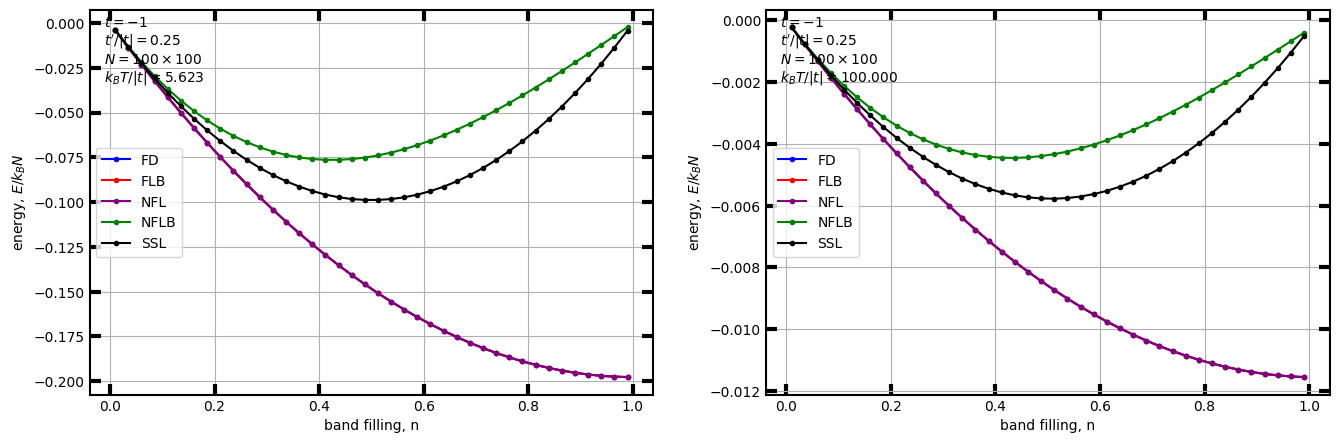

In [8]:
H_a_plot = H_a[0] 
beta_plot = 1/k_BT[-2:]

# Plotimport scientific_plot as sp
sp.plot_result_n(
    results=energy_df,
    n=n,
    betas=beta_plot,
    y_label=r"energy, $E / k_B N$",
    distros=distro,
    H_a=H_a_plot,
    y_col="energy",  # Specify the column to plot
    legend_position="center left",
    figsize=(8, 5),
    cols=2 # Adjust columns for layout
)
plt.show()

## Free energy

$$ \frac{F}{N |t|} =  \frac{1}{N |t|}  \sum_k \epsilon_k n_k - \frac{k_bT}{|t|} \frac{S}{k_bN}$$


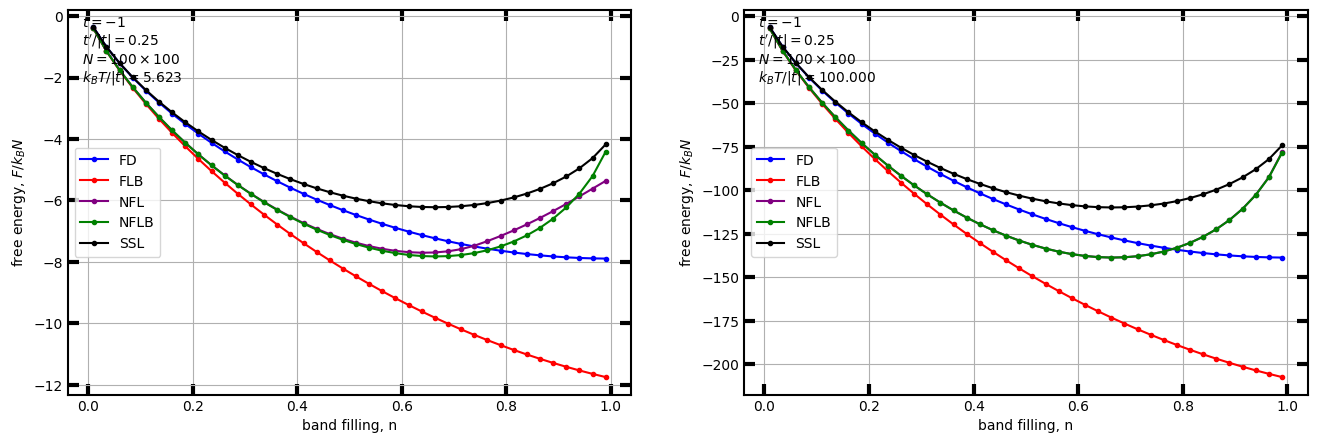

In [7]:
H_a_plot = H_a[0] 
beta_plot = 1/k_BT[-2:]

# Plotimport scientific_plot as sp
sp.plot_result_n(
    results=energy_df,
    n=n,
    betas=beta_plot,
    y_label=r"free energy, $F / k_B N$",
    distros=distro,
    H_a=H_a_plot,
    y_col="free_energy",  # Specify the column to plot
    legend_position="center left",
    figsize=(8, 5),
    cols=2 # Adjust columns for layout
)
plt.show()